C:\Users\allan\AppData\Local\Temp\ipykernel_10244\2831332162.py:82: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


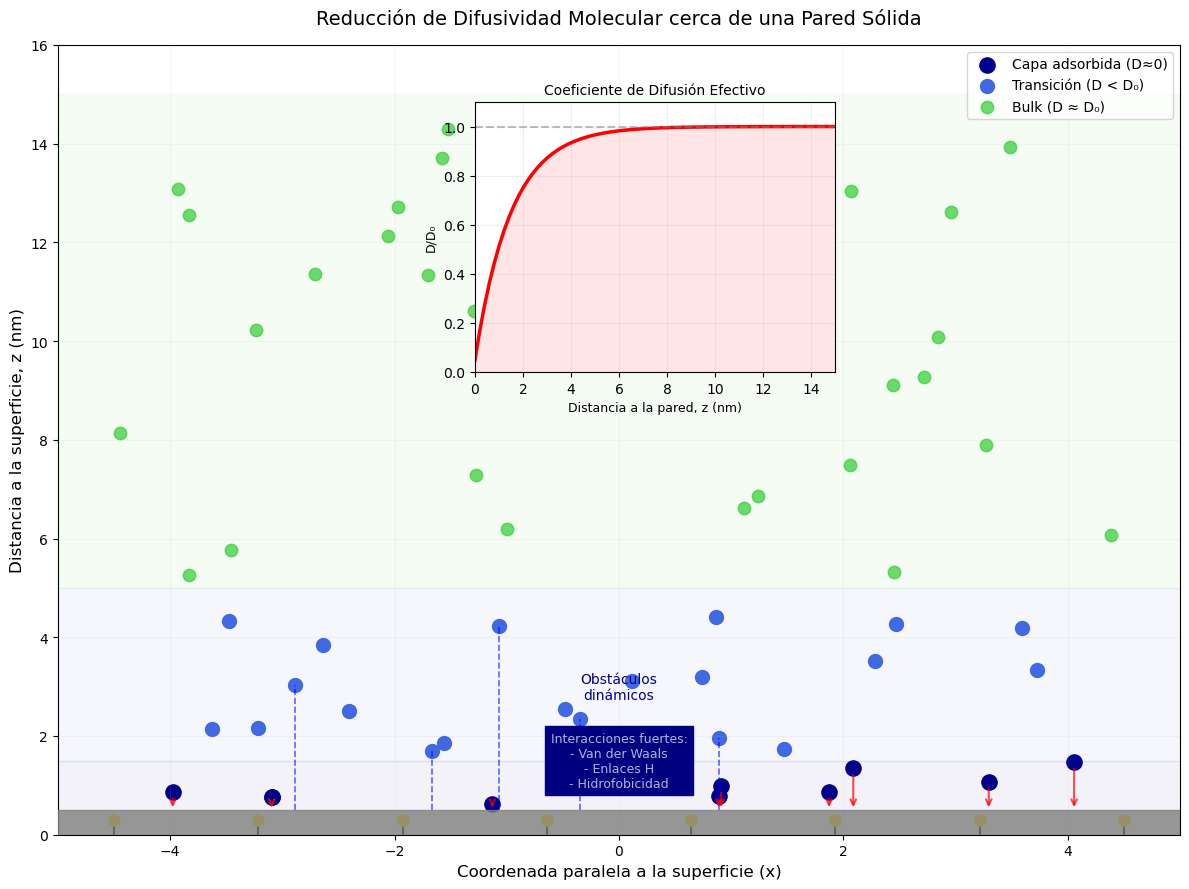

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, FancyArrowPatch
from matplotlib.collections import LineCollection

# Configuración de la figura
fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111)

# 1. Pared sólida (gris)
wall = Rectangle((-5, 0), 10, 0.5, color='#7f7f7f', alpha=0.8, zorder=10)
ax.add_patch(wall)

# 2. Moléculas en diferentes capas
np.random.seed(42)

# Capa adsorbida (inmóvil)
x_ads = np.random.uniform(-4.5, 4.5, 10)
z_ads = np.random.uniform(0.6, 1.5, 10)
ads = ax.scatter(x_ads, z_ads, c='darkblue', s=120, label='Capa adsorbida (D≈0)')

# Capa de transición (movimiento restringido)
x_trans = np.random.uniform(-4, 4, 20)
z_trans = np.random.uniform(1.6, 4.5, 20)
trans = ax.scatter(x_trans, z_trans, c='royalblue', s=100, label='Transición (D < D₀)')

# Bulk (movimiento libre)
x_bulk = np.random.uniform(-4.5, 4.5, 30)
z_bulk = np.random.uniform(5, 15, 30)
bulk = ax.scatter(x_bulk, z_bulk, c='limegreen', s=80, alpha=0.7, label='Bulk (D ≈ D₀)')

# 3. Fuerzas de Van der Waals (flechas desde moléculas hasta la pared)
for i in range(len(x_ads)):
    ax.annotate('', 
                xy=(x_ads[i], 0.5),      # Punto final (pared)
                xytext=(x_ads[i], z_ads[i]), # Punto inicial (molécula)
                arrowprops=dict(arrowstyle='->', color='red', lw=1.5, alpha=0.7, shrinkA=5))

# 4. Enlaces de hidrógeno (líneas discontinuas)
for i in range(5):  # Solo para algunas moléculas
    ax.plot([x_trans[i], x_trans[i]], [0.5, z_trans[i]], 
            'b--', lw=1.2, alpha=0.6)

# 5. Grupos hidrofóbicos (cadenas en la superficie)
for x in np.linspace(-4.5, 4.5, 8):
    ax.plot([x, x], [0, 0.3], 'k-', lw=1.5)  # Cadenas hidrofóbicas
    ax.plot(x, 0.3, 'o', markersize=8, color='gold')  # Grupo terminal

# 6. Gráfico de difusividad inserto
ax_inset = fig.add_axes([0.40, 0.58, 0.3, 0.3])
z_vals = np.linspace(0, 20, 100)
D_vals = 1 - 0.95*np.exp(-z_vals/1.5)  # Perfil exponencial realista
ax_inset.plot(z_vals, D_vals, 'r-', lw=2.5)
ax_inset.fill_between(z_vals, 0, D_vals, color='red', alpha=0.1)
ax_inset.axhline(y=1, color='gray', linestyle='--', alpha=0.5)
ax_inset.set_xlabel('Distancia a la pared, z (nm)', fontsize=9)
ax_inset.set_ylabel('D/D₀', fontsize=9)
ax_inset.set_title('Coeficiente de Difusión Efectivo', fontsize=10)
ax_inset.grid(alpha=0.2)
ax_inset.set_xlim(0, 15)
ax_inset.set_ylim(0, 1.1)

# 7. Etiquetas y estilo final
ax.set_xlabel('Coordenada paralela a la superficie (x)', fontsize=12)
ax.set_ylabel('Distancia a la superficie, z (nm)', fontsize=12)
ax.set_title('Reducción de Difusividad Molecular cerca de una Pared Sólida', fontsize=14, pad=15)
ax.legend(loc='upper right', fontsize=10)
ax.set_xlim(-5, 5)
ax.set_ylim(0, 16)
ax.grid(alpha=0.1)

# Líneas divisorias de capas
ax.axhspan(0, 1.5, color='navy', alpha=0.05)     # Capa adsorbida
ax.axhspan(1.5, 5, color='royalblue', alpha=0.05) # Transición
ax.axhspan(5, 15, color='limegreen', alpha=0.05)  # Bulk

# Textos explicativos
ax.text(0, 1.5, 'Interacciones fuertes:\n- Van der Waals\n- Enlaces H\n- Hidrofobicidad', 
        color='white', ha='center', va='center', fontsize=9, backgroundcolor='navy', alpha=0.7)
ax.text(0, 3, 'Obstáculos\ndinámicos', color='darkblue', ha='center', va='center', fontsize=10)

plt.tight_layout()
plt.savefig("figuras/diagrama_difusión.pdf", bbox_inches="tight", dpi=300)
plt.show()
plt.close()